# 03. ViT-Small laboratory baseline

This experiment trains `vit_small_patch16_224.augreg_in1k` on the same Lab Train (5,365) and Lab Validation (1,341) manifests as ResNet18. The ImageNet-1k-pretrained model uses 224 × 224 inputs and no stochastic image augmentation; selection maximizes Lab Validation macro-F1.

The shared partitions, class mapping, seed, and eight-epoch budget support a comparison of these two training configurations. Architecture, parameter count, pretraining recipe, batch size, learning rates, and preprocessing differ, so their effects are not isolated.

## Runtime and source

The saved run uses a Colab Tesla T4, PyTorch `2.10.0+cu128`, and timm `1.0.26`. Results are stored in `vit_small_baseline/` under `/content/drive/MyDrive/plant-disease-diagnosis/`. The setup cells clone or update the source checkout.

In [1]:
%pip install -q timm datasets scikit-learn pandas matplotlib pillow

In [2]:
from pathlib import Path
import subprocess, sys, json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader
from torch.amp import autocast, GradScaler
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import timm

REPO_URL = "https://github.com/thutrang147/plant-disease-diagnosis.git"
PROJECT_ROOT = Path("/content/plant-disease-diagnosis")
if not PROJECT_ROOT.exists():
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(PROJECT_ROOT)], check=True)
else:
    subprocess.run(["git", "-C", str(PROJECT_ROOT), "pull", "--ff-only"], check=True)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.dataset import PlantDiseaseDataset
from google.colab import drive
drive.mount("/content/drive")

assert torch.cuda.is_available(), "Select a Colab GPU runtime before training."
DEVICE = torch.device("cuda")
print("GPU:", torch.cuda.get_device_name(0))
print("torch", torch.__version__, "timm", timm.__version__)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: Tesla T4
torch 2.10.0+cu128 timm 1.0.26


## Experimental configuration

Seed 42, batch size 16, three head epochs, and five full fine-tuning epochs are defined below. Existing manifests and label order are reused. Lab Test and Field Test do not enter training or checkpoint selection in this notebook.

In [3]:
SEED = 42
BATCH_SIZE = 16
HEAD_EPOCHS = 3
FINETUNE_EPOCHS = 5
MODEL_NAME = "vit_small_patch16_224.augreg_in1k"
NUM_WORKERS = 0
SPLITS_DIR = PROJECT_ROOT / "data" / "splits"
RESULTS_DIR = Path("/content/drive/MyDrive/plant-disease-diagnosis/vit_small_baseline")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

label_map = json.loads((SPLITS_DIR / "label_map.json").read_text())
CLASS_NAMES = [name for name, i in sorted(label_map.items(), key=lambda kv: kv[1])]
assert len(CLASS_NAMES) == 5 and sorted(label_map.values()) == list(range(5))
print("Class names:", CLASS_NAMES)
print("Saving results in:", RESULTS_DIR)

Class names: ['Healthy', 'Early Blight', 'Late Blight', 'Bacterial Spot', 'Septoria Leaf Spot']
Saving results in: /content/drive/MyDrive/plant-disease-diagnosis/vit_small_baseline


## Model and preprocessing

The five-class ViT has 21,667,589 parameters. timm resolves its evaluation transform: bicubic resize to 248, center crop to 224, and normalization with mean and standard deviation 0.5 per channel. The same deterministic transform is used for training and validation.

In [4]:
model = timm.create_model(MODEL_NAME, pretrained=True, num_classes=len(CLASS_NAMES))
data_config = timm.data.resolve_model_data_config(model)
preprocess = timm.data.create_transform(**data_config, is_training=False)
assert tuple(data_config["input_size"]) == (3, 224, 224)
model = model.to(DEVICE)

train_ds = PlantDiseaseDataset(SPLITS_DIR / "lab_train.csv", transform=preprocess)
val_ds = PlantDiseaseDataset(SPLITS_DIR / "lab_val.csv", transform=preprocess)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=True)
print("Training images:", len(train_ds), "Validation images:", len(val_ds))
print("Preprocessing:", preprocess)
x, y = next(iter(train_loader))
print("First batch shape:", x.shape, y.shape)
assert x.shape[1:] == (3, 224, 224)
assert int(y.min()) >= 0 and int(y.max()) < len(CLASS_NAMES)

head = model.get_classifier()
print("Model parameters:", sum(p.numel() for p in model.parameters()))
print("Classification head:", head)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


model.safetensors:   0%|          | 0.00/88.2M [00:00<?, ?B/s]

Training images: 5365 Validation images: 1341
Preprocessing: Compose(
    Resize(size=248, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    MaybeToTensor()
    Normalize(mean=tensor([0.5000, 0.5000, 0.5000]), std=tensor([0.5000, 0.5000, 0.5000]))
)
First batch shape: torch.Size([16, 3, 224, 224]) torch.Size([16])
Model parameters: 21667589
Classification head: Linear(in_features=384, out_features=5, bias=True)


## Optimization and selection

Cross-entropy training uses automatic mixed precision. Per-epoch validation runs without gradients; the checkpoint is saved when five-class Lab Validation macro-F1 increases.

In [5]:
criterion = nn.CrossEntropyLoss()
scaler = GradScaler("cuda")
HISTORY = []
BEST_F1 = -1.0
CHECKPOINT = RESULTS_DIR / "vit_small_lab_best.pt"


def run_epoch(loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, true, predicted = 0.0, [], []
    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        if training:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            with autocast(device_type="cuda", dtype=torch.float16):
                logits = model(images)
                loss = criterion(logits, labels)
            if training:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
        total_loss += float(loss.detach()) * len(labels)
        true.extend(labels.detach().cpu().tolist())
        predicted.extend(logits.detach().argmax(1).cpu().tolist())
    return {
        "loss": total_loss / len(loader.dataset),
        "accuracy": accuracy_score(true, predicted),
        "macro_f1": f1_score(true, predicted, labels=list(range(5)), average="macro", zero_division=0),
    }


def train_phase(phase, n_epochs, optimizer):
    global BEST_F1
    for epoch in range(1, n_epochs + 1):
        train_metrics = run_epoch(train_loader, optimizer=optimizer)
        val_metrics = run_epoch(val_loader)
        record = {
            "phase": phase, "epoch_in_phase": epoch,
            "train_loss": train_metrics["loss"],
            "train_accuracy": train_metrics["accuracy"],
            "train_macro_f1": train_metrics["macro_f1"],
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "val_macro_f1": val_metrics["macro_f1"],
        }
        HISTORY.append(record)
        pd.DataFrame(HISTORY).to_csv(RESULTS_DIR / "training_history.csv", index=False)
        if val_metrics["macro_f1"] > BEST_F1:
            BEST_F1 = val_metrics["macro_f1"]
            torch.save({
                "model_state_dict": model.state_dict(),
                "architecture": MODEL_NAME,
                "pretrained_weights": "augreg_in1k",
                "class_names": CLASS_NAMES,
                "best_val_macro_f1": BEST_F1,
                "phase": phase,
                "epoch_in_phase": epoch,
                "seed": SEED,
                "preprocessing_config": data_config,
            }, CHECKPOINT)
        print(f"{phase} {epoch}/{n_epochs}: train F1={train_metrics['macro_f1']:.4f}, "
              f"val F1={val_metrics['macro_f1']:.4f}, val loss={val_metrics['loss']:.4f}, "
              f"best F1={BEST_F1:.4f}")

## Classifier-head optimization

The backbone is frozen for three epochs; AdamW trains the replacement head with learning rate `1e-3` and weight decay `1e-4`. Saved Lab Validation macro-F1 rises from 0.9470 to 0.9673.

In [6]:
for parameter in model.parameters():
    parameter.requires_grad = False
for parameter in model.get_classifier().parameters():
    parameter.requires_grad = True
head_optimizer = torch.optim.AdamW(model.get_classifier().parameters(), lr=1e-3, weight_decay=1e-4)
train_phase("classifier_head", HEAD_EPOCHS, head_optimizer)

classifier_head 1/3: train F1=0.8583, val F1=0.9470, val loss=0.1829, best F1=0.9470
classifier_head 2/3: train F1=0.9463, val F1=0.9658, val loss=0.1299, best F1=0.9658
classifier_head 3/3: train F1=0.9652, val F1=0.9673, val loss=0.1083, best F1=0.9673


## Full-model fine-tuning

All parameters are unfrozen for five epochs. AdamW uses learning rates `1e-5` for the backbone and `5e-5` for the head. Lab Validation macro-F1 reaches approximately 0.9966 while training macro-F1 reaches 1.0000.

In [7]:
for parameter in model.parameters():
    parameter.requires_grad = True
head_ids = {id(p) for p in model.get_classifier().parameters()}
backbone_parameters = [p for p in model.parameters() if id(p) not in head_ids]
finetune_optimizer = torch.optim.AdamW([
    {"params": backbone_parameters, "lr": 1e-5},
    {"params": model.get_classifier().parameters(), "lr": 5e-5},
], weight_decay=1e-4)
train_phase("full_finetune", FINETUNE_EPOCHS, finetune_optimizer)

full_finetune 1/5: train F1=0.9816, val F1=0.9957, val loss=0.0235, best F1=0.9957
full_finetune 2/5: train F1=0.9992, val F1=0.9959, val loss=0.0198, best F1=0.9959
full_finetune 3/5: train F1=1.0000, val F1=0.9966, val loss=0.0171, best F1=0.9966
full_finetune 4/5: train F1=1.0000, val F1=0.9966, val loss=0.0167, best F1=0.9966
full_finetune 5/5: train F1=1.0000, val F1=0.9966, val loss=0.0164, best F1=0.9966


## Training trajectory

Validation loss declines from 0.0235 to 0.0164 during full fine-tuning; macro-F1 remains approximately 0.9966 over the last three epochs. This trajectory describes source-domain fitting and does not establish generalization under domain shift.

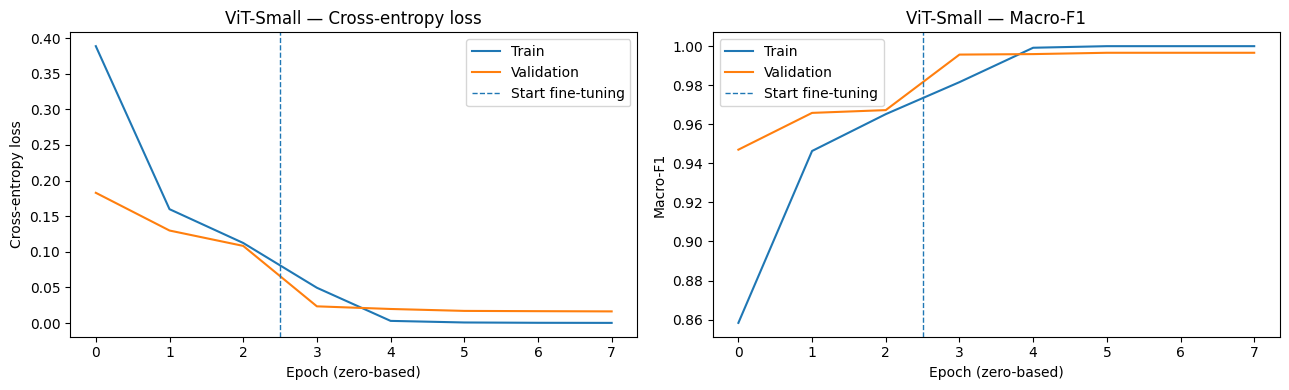

Best validation macro-F1: 0.9966


In [8]:
history_df = pd.DataFrame(HISTORY)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for key, ax, ylabel in [
    ("loss", axes[0], "Cross-entropy loss"),
    ("macro_f1", axes[1], "Macro-F1"),
]:
    ax.plot(history_df[f"train_{key}"].to_numpy(), label="Train")
    ax.plot(history_df[f"val_{key}"].to_numpy(), label="Validation")
    ax.axvline(HEAD_EPOCHS - 0.5, linestyle="--", linewidth=1, label="Start fine-tuning")
    ax.set_title(f"ViT-Small — {ylabel}")
    ax.set_xlabel("Epoch (zero-based)")
    ax.set_ylabel(ylabel)
    ax.legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / "training_curves.png", dpi=160)
plt.show()
print("Best validation macro-F1:", round(BEST_F1, 4))

## Selected-checkpoint validation

The saved best state is reloaded for class-level metrics and the confusion matrix on Lab Validation. These are validation results from the partition used for checkpoint selection.

                    precision    recall  f1-score   support

           Healthy     0.9960    0.9960    0.9960       253
      Early Blight     1.0000    0.9875    0.9937       160
       Late Blight     0.9935    0.9967    0.9951       306
    Bacterial Spot     1.0000    1.0000    1.0000       340
Septoria Leaf Spot     0.9965    1.0000    0.9982       282

          accuracy                         0.9970      1341
         macro avg     0.9972    0.9961    0.9966      1341
      weighted avg     0.9970    0.9970    0.9970      1341



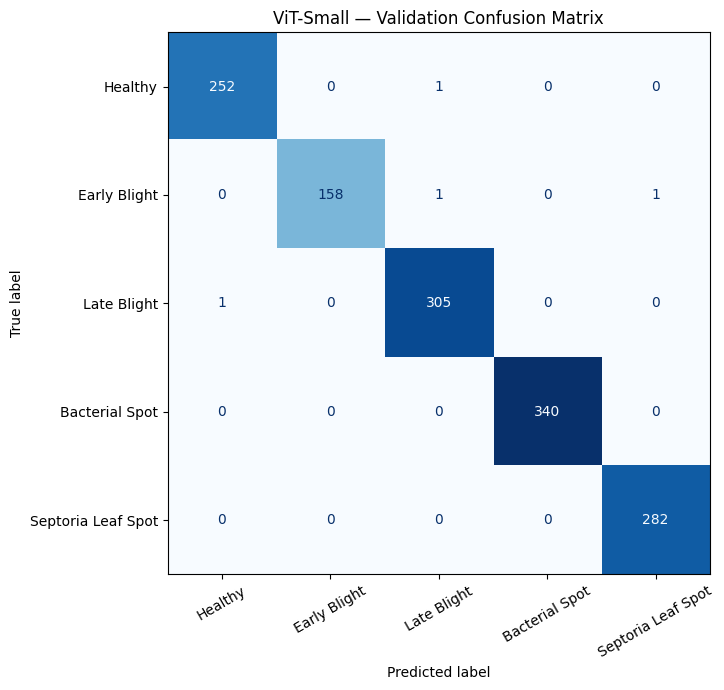

Checkpoint: /content/drive/MyDrive/plant-disease-diagnosis/vit_small_baseline/vit_small_lab_best.pt
Best val macro-F1: 0.996618849407717


In [9]:
checkpoint = torch.load(CHECKPOINT, map_location="cpu", weights_only=True)
assert checkpoint["class_names"] == CLASS_NAMES
model.load_state_dict(checkpoint["model_state_dict"], strict=True)
model.to(DEVICE).eval()
true, predicted = [], []
with torch.inference_mode():
    for images, labels in val_loader:
        with autocast(device_type="cuda", dtype=torch.float16):
            logits = model(images.to(DEVICE, non_blocking=True))
        predicted.extend(logits.argmax(dim=1).cpu().tolist())
        true.extend(labels.tolist())
report = classification_report(true, predicted, labels=list(range(5)),
                               target_names=CLASS_NAMES, zero_division=0, digits=4)
print(report)
(RESULTS_DIR / "validation_classification_report.txt").write_text(report, encoding="utf-8")
cm = confusion_matrix(true, predicted, labels=list(range(5)))
fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(
    ax=ax, cmap="Blues", colorbar=False, xticks_rotation=30)
ax.set_title("ViT-Small — Validation Confusion Matrix")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "validation_confusion_matrix.png", dpi=160)
plt.show()
print("Checkpoint:", CHECKPOINT)
print("Best val macro-F1:", checkpoint["best_val_macro_f1"])

## Results and interpretation

ViT-Small achieves Lab Validation macro-F1 0.9966 and accuracy 0.9970 on 1,341 images, compared with ResNet18's 0.9879 and 0.9896. Early Blight has the lowest ViT per-class F1 (0.9937); Bacterial Spot has F1 1.0000 on 340 validation examples.

Full fine-tuning improves on the head-only macro-F1 of 0.9673. Training macro-F1 reaches 1.0000 without a decline in the saved validation macro-F1, but this does not exclude overfitting beyond the laboratory sample. Notebook 04 reports the frozen baseline comparison on Lab Test and the original Field Test.